# Example 3.5 — Protein complexes: GABA-A receptor subtypes

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:22Z
- **Contents:** 1 exchange · 14 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/3.5-protein-complexes-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 3.5-protein-complexes-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 3.5-protein-complexes-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/3.5-protein-complexes-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 3.5-protein-complexes-notebook-rerun.ipynb 3.5-protein-complexes-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

The benzodiazepine binding site sits between two subunits of the GABA-A receptor. How does BindingDB store a target like that, and how selective are the benzodiazepine-site drugs across the subtypes?

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:55:21 UTC
await replay.call(1, 'search_targets', {'query': 'GABA-A receptor'},
                  sha256='9f9d7a0b3e6e080bbf334689053300d792e2e00801a43510d8965fa413ffcac8')

**Call 1** · `search_targets` · recorded result · sha256 `9f9d7a0b3e6e…`

_17 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 5521 | Gamma-aminobutyric acid receptor subunit alpha-1 | P14867 | P14867 | Homo sapiens | Protein | 540 | 447 | GABA-A receptor |
| polymer | 49000543 | Gamma-aminobutyric acid receptor subunit alpha-3 | P34903 | P34903 | Homo sapiens | Enzyme Catalytic Domain | 151 | 130 | GABA-A receptor |
| polymer | 50001801 | Gamma-aminobutyric acid receptor subunit beta-3 | P28472 | P28472 | Homo sapiens | PROTEIN | 20 | 18 | GABA-A receptor |
| complex | 50000048 | GABA-A receptor; alpha-5/beta-3/gamma-2 |  |  |  |  | 1383 | 1213 | GABA-A receptor; alpha-5/beta-3/gamma-2 |
| complex | 386 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-3/gamma-2 |  |  |  | Protein | 1325 | 1111 | GABA-A receptor; alpha-1/beta-3/gamma-2 |
| complex | 50000037 | Gamma-aminobutyric acid receptor subunit alpha-3/beta-3/gamma-2 |  |  |  |  | 899 | 734 | GABA-A receptor; alpha-3/beta-3/gamma-2 |
| complex | 50000045 | GABA-A receptor; alpha-2/beta-3/gamma-2 |  |  |  |  | 779 | 617 | GABA-A receptor; alpha-2/beta-3/gamma-2 |
| complex | 347 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-2/gamma-2 |  |  |  | Protein | 416 | 307 | GABA-A receptor; alpha-1/beta-2/gamma-2 |
| complex | 50000040 | Gamma-aminobutyric acid receptor subunit alpha-6/beta-3/gamma-2 |  |  |  |  | 317 | 216 | GABA-A receptor; alpha-6/beta-3/gamma-2 |
| complex | 50000068 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-2/gamma-2 |  |  |  |  | 103 | 85 | GABA-A receptor; alpha-1/beta-2/gamma-2 |
| complex | 50000041 | GABA-A receptor; alpha-1/beta-3/gamma-2 |  |  |  |  | 31 | 21 | GABA-A receptor; alpha-1/beta-3/gamma-2 |
| complex | 50000411 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-2 |  |  |  |  | 30 | 30 | GABA-A receptor; GABA-A site (alpha1/beta2 interface) |
| polymer | 49000570 | GABA(A) receptor-associated protein |  |  | Sus scrofa | Enzyme Catalytic Domain | 11 | 10 | GABA-A receptor subunit alpha 1 |
| polymer | 50001470 | Gamma-aminobutyric acid receptor subunit alpha-1 | P62812 | P62812 | Mus musculus | PROTEIN | 3 | 3 | GABA-A receptor; anion channel |
| complex | 50000081 | GABA-A receptor; alpha-1/beta-2/gamma-2 |  |  |  |  | 2 | 2 | GABA-A receptor; alpha-1/beta-2/gamma-2 |
| complex | 50000103 | GABA-A receptor alpha-1/beta-3 |  |  |  |  | 2 | 2 | GABA-A receptor alpha-1/beta-3 |
| complex | 50000910 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-1 |  |  |  |  | 1 | 1 | GABA-A receptor alpha-1/beta-1 |


In [ ]:
# Call 2 · get_target · ran 2026-11-24 04:55:21 UTC
await replay.call(2, 'get_target', {'target_id': 386, 'target_kind': 'complex'},
                  sha256='9978a7242823e62bbdf7992fc2b1135d8a2dd948692d6e8390edc065e4109aa9')

**Call 2** · `get_target` · recorded result · sha256 `9978a7242823…`

```json
{
  "target": {
    "target_kind": "complex",
    "target_id": 386,
    "name": "Gamma-aminobutyric acid receptor subunit alpha-1/beta-3/gamma-2",
    "uniprot": null,
    "uniprot_raw": null,
    "organism": null,
    "taxid": null,
    "type": "Protein",
    "res_count": null,
    "n_pdb_ids": 153,
    "chembl_id": null,
    "n_activities": 1325,
    "n_compounds": 1111,
    "pdb_ids": "9EQG,9CXA,7QNE,7QND,7QNC,7QNB,7QNA,7QN9,7QN8,7QN7,7QN6,7QN5,9CXC,9CX7,9CTJ,9CSB,9FGH,9FGG,9FGF,9FGD,9FGC,9FGB,9FGA,9FG9,9FG8,9FG7,9FG6,9FG5,9FG4,6I53,6HUP,6HUO,6HUK,6HUJ,6HUG,8PET,9FAW,9RGD,9FAT,9FAS,9FAM,9FAK,9FAJ,9RGE,9FAX,9FAV,9FAU,9FAQ,9FAP,9RPB,9RL5,9HUM,9HNT,9HNS,9HNR,9HNQ,9HAA,6A96,4COF,9G2E,9G2D,9FG3,9FG2,9FG1,9FFZ,9FFY,9FFX,9FFW,9FFV,9FFU,9FFT,9FFS,9FFR,9FFQ,9FFP,9FFO,9FFN,9FFM,9FFL,9FF2,9FF1,9FEZ,9FEY,9FEX,9FEW,9FEV,9FEU,6QFA,8PVB,7A5V,9FF0,9FG0,6DW1,6DW0,6D6U,6D6T,7T0Z,7T0W,9YNN,9DRX,8VRN,8VQY,8SID,8SI9,8SGO,8DD3,8DD2,6X40,6X3Z,6X3X,6X3W,6X3V,6X3U,6X3T,6X3S,9OV4,9OUR,9OUQ,9OUP,9OUO,9OUN,9OUM,8G5H,8G5G,8G5F,8G4X,8G4O,8G4N,8FOI,9CXD,9CXB,9CTV,9CTP,9CT0,9CRV,9CRS,9TPQ,9TNS,9TNB,9QK0,9QJY,9QJX,9QJP,8BHG,9H9E,7PC0,7PBZ,7PBD,9QK1,9QJV,9QJS,9QJR,9QJQ",
    "comments": null
  },
  "synonyms": [
    "GABAA alpha1beta3gamma2",
    "GABA-A receptor; alpha-1/beta-3/gamma-2",
    "GABA receptor alpha-1/beta-3/gamma-2 subunit",
    "Gamma-aminobutyric acid receptor subunit alpha-1/beta-3/gamma-2"
  ]
}
```

**measurements_by_type**: 3 rows

| affinity_type | n_measurements | n_compounds | best_p_affinity |
| --- | --- | --- | --- |
| Ki | 1258 | 1065 | 10.3 |
| EC50 | 55 | 45 | 6.6 |
| IC50 | 12 | 6 | 6.4 |

**components**: 3 rows

| type | polymerid | polymer_name | uniprot_raw | monomerid |
| --- | --- | --- | --- | --- |
| Protein | 5521 | Gamma-aminobutyric acid receptor subunit alpha-1 | P14867 |  |
| Protein | 50000214 | Gamma-aminobutyric acid receptor subunit gamma-2 | P18507 |  |
| Protein | 50001801 | Gamma-aminobutyric acid receptor subunit beta-3 | P28472 |  |


In [ ]:
# Call 3 · run_sql · ran 2026-11-24 04:55:21 UTC
sql = """
    select target_id, name, n_compounds, n_activities from target where target_kind='complex' and (name ilike '%GABA%' or name ilike '%aminobutyric%') and name not ilike '%transporter%' and name not ilike '% B receptor%' order by n_activities desc, target_id
    
"""
await replay.call(3, 'run_sql', {'sql': sql},
                  sha256='81f7c6ece387135886c68f748131cfecbda7096201f07394f9a260f395161728')

**Call 3** · `run_sql` · recorded result · sha256 `81f7c6ece387…`

_87 rows_

| target_id | name | n_compounds | n_activities |
| --- | --- | --- | --- |
| 50000048 | GABA-A receptor; alpha-5/beta-3/gamma-2 | 1213 | 1383 |
| 386 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-3/gamma-2 | 1111 | 1325 |
| 50000037 | Gamma-aminobutyric acid receptor subunit alpha-3/beta-3/gamma-2 | 734 | 899 |
| 50000045 | GABA-A receptor; alpha-2/beta-3/gamma-2 | 617 | 779 |
| 384 | Gamma-aminobutyric acid receptor subunit alpha-2/beta-2/gamma-1 | 394 | 651 |
| 347 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-2/gamma-2 | 307 | 416 |
| 382 | Gamma-aminobutyric acid receptor subunit alpha-5/beta-2/gamma-1 | 385 | 390 |
| 50000040 | Gamma-aminobutyric acid receptor subunit alpha-6/beta-3/gamma-2 | 216 | 317 |
| 385 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-2/gamma-1 | 142 | 157 |
| 50000071 | Gamma-aminobutyric acid receptor subunit alpha-2/beta-2/gamma-2 | 121 | 131 |
| 50000068 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-2/gamma-2 | 85 | 103 |
| 50000072 | Gamma-aminobutyric acid receptor subunit alpha-3/beta-2/gamma-2 | 54 | 66 |
| 50000150 | Gamma-aminobutyric acid receptor subunit alpha-5/beta-2/gamma-2 | 43 | 65 |
| 50000047 | GABA A receptor alpha-4/beta-3/gamma-2 | 61 | 63 |
| 50000106 | Gamma-aminobutyric acid receptor subunit alpha-6/beta-2/gamma-2 | 14 | 37 |
| 50000146 | Gamma-aminobutyric acid receptor subunit alpha-5/beta-3/gamma-2 | 36 | 36 |
| 50016995 | Gamma-aminobutyric acid receptor subunit alpha-6/beta-3/gamma-2 | 20 | 32 |
| 50000041 | GABA-A receptor; alpha-1/beta-3/gamma-2 | 21 | 31 |
| 50000411 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-2 | 30 | 30 |
| 50017444 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-3/gamma-2 | 14 | 28 |
| 50000038 | Gamma-aminobutyric acid receptor subunit alpha-3/beta-2/gamma-2 | 20 | 26 |
| 50000020 | Gamma-aminobutyric acid receptor subunit alpha-2/beta-2/gamma-2 | 22 | 25 |
| 50000010 | Gamma-aminobutyric acid receptor subunit alpha-6/beta-2/gamma-2 | 17 | 20 |
| 438 | Gamma-aminobutyric acid receptor subunit alpha-1/Adenosine receptor A1 | 19 | 19 |
| 50000043 | GABA A receptor alpha-1/beta-1/gamma-2 | 11 | 18 |
| 50003702 | Gamma-aminobutyric acid receptor subunit alpha-4/beta-2/gamma-2 | 9 | 18 |
| 50004460 | Gamma-aminobutyric acid receptor subunit alpha-2/delta | 17 | 17 |
| 50000132 | Gamma-aminobutyric acid receptor subunit alpha-4/beta-1/delta | 10 | 14 |
| 50017847 | Gamma-aminobutyric acid receptor subunit beta-1/beta-2 | 14 | 14 |
| 50015477 | Gamma-aminobutyric acid receptor subunit alpha-4/beta-3/delta | 12 | 12 |
| 226 | Gamma-aminobutyric acid receptor subunit alpha-5 \[32-462\]/beta-3 \[26-473\]/gamma-2 \[40-467\] | 11 | 11 |
| 50016994 | Gamma-aminobutyric acid receptor subunit alpha-6/beta-3/delta | 7 | 10 |
| 50016993 | Gamma-aminobutyric acid receptor subunit alpha-6/beta-3 | 7 | 9 |
| 222 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-3 \[26-473\]/gamma-2 \[40-467\] | 8 | 8 |
| 223 | Gamma-aminobutyric acid receptor subunit alpha-2 \[29-451\]/beta-3 \[26-473\]/gamma-2 \[40-467\] | 8 | 8 |
| 50000121 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-2/delta | 4 | 8 |
| 224 | Gamma-aminobutyric acid receptor subunit alpha-3 \[29-492\]/beta-3 \[26-473\]/gamma-2 \[40-467\] | 7 | 7 |
| 227 | Gamma-aminobutyric acid receptor subunit alpha-6 \[20-453\]/beta-3 \[26-473\]/gamma-2 \[40-467\] | 7 | 7 |
| 50017008 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-3/gamma-2 | 4 | 6 |
| 50000177 | Gamma-aminobutyric acid receptor subunit alpha-1/alpha-6/beta-3/gamma-2 | 2 | 5 |
| 50017006 | Gamma-aminobutyric acid receptor subunit alpha-6/beta-2/delta | 4 | 5 |
| 225 | Gamma-aminobutyric acid receptor subunit alpha-4 \[36-554\]/beta-3 \[26-473\]/gamma-2 \[40-467\] | 4 | 4 |
| 228 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 229 | Gamma-aminobutyric acid receptor subunit alpha-2 \[29-451\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 230 | Gamma-aminobutyric acid receptor subunit alpha-3 \[29-492\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 231 | Gamma-aminobutyric acid receptor subunit alpha-5 \[32-462\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 232 | Gamma-aminobutyric acid receptor subunit alpha-4 \[36-554\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 233 | Gamma-aminobutyric acid receptor subunit alpha-6 \[20-453\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 235 | Gamma-aminobutyric acid receptor subunit alpha-1 \[F99C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 236 | Gamma-aminobutyric acid receptor subunit alpha-1 \[G157C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 237 | Gamma-aminobutyric acid receptor subunit alpha-1 \[A160C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 238 | Gamma-aminobutyric acid receptor subunit alpha-1 \[T162C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 239 | Gamma-aminobutyric acid receptor subunit alpha-1 \[G200C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 240 | Gamma-aminobutyric acid receptor subunit alpha-1 \[V202C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 241 | Gamma-aminobutyric acid receptor subunit alpha-1 \[S204C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 242 | Gamma-aminobutyric acid receptor subunit alpha-1 \[S205C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 243 | Gamma-aminobutyric acid receptor subunit alpha-1 \[T206C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 245 | Gamma-aminobutyric acid receptor subunit alpha-1 \[V211C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 3 | 3 |
| 246 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,D95C\] | 3 | 3 |
| 248 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,A118C\] | 3 | 3 |
| 249 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,T120C\] | 3 | 3 |
| 250 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,T165C\] | 3 | 3 |
| 251 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,M169C\] | 3 | 3 |
| 252 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,R171C\] | 3 | 3 |
| 253 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,L179C\] | 3 | 3 |
| 254 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,T181C\] | 3 | 3 |
| 255 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,R183C\] | 3 | 3 |
| 256 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-200\],P14867\[176-456\] | 3 | 3 |
| 257 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,R224C\] | 3 | 3 |
| 258 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,R233C\] | 3 | 3 |
| 50017011 | Gamma-aminobutyric acid receptor subunit alpha-4/beta-3/delta | 2 | 3 |
| 50000081 | GABA-A receptor; alpha-1/beta-2/gamma-2 | 2 | 2 |
| 50000103 | GABA-A receptor alpha-1/beta-3 | 2 | 2 |
| 50000178 | Gamma-aminobutyric acid receptor subunit alpha-2/beta-1/gamma-2 | 2 | 2 |
| 50016679 | Gamma-aminobutyric acid receptor subunit alpha-2/beta-3/gamma-2 | 2 | 2 |
| 50016680 | Gamma-aminobutyric acid receptor subunit alpha-3/beta-3/gamma-2 | 2 | 2 |
| 50017009 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-3/delta | 2 | 2 |
| 50017010 | Gamma-aminobutyric acid receptor subunit alpha-4/beta-3 | 1 | 2 |
| 50017023 | Gamma-aminobutyric acid receptor subunit alpha-6/beta-2 | 2 | 2 |
| 50000910 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-1 | 1 | 1 |
| 50001488 | Gamma-aminobutyric acid receptor subunit alpha-1/gamma-2 | 1 | 1 |
| 50016997 | Gamma-aminobutyric acid receptor subunit alpha-4/beta-3/gamma-2 | 1 | 1 |
| 50017029 | Gamma-aminobutyric acid receptor subunit alpha-1/beta-3 | 1 | 1 |
| 50017448 | Gamma-aminobutyric acid receptor subunit alpha-4/beta-2/delta | 1 | 1 |
| 234 | Gamma-aminobutyric acid receptor subunit alpha-1 \[D97C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 0 | 0 |
| 244 | Gamma-aminobutyric acid receptor subunit alpha-1 \[Y209C\]/beta-2 \[26-512\]/gamma-2 \[40-467\] | 0 | 0 |
| 247 | Gamma-aminobutyric acid receptor subunit alpha-1 \[28-456\]/beta-2 \[26-512\]/gamma-2 \[40-467,F116C\] | 0 | 0 |


In [ ]:
# Call 4 · run_sql · ran 2026-11-24 04:55:21 UTC
sql = """
    select count(distinct a.monomerid) n, count(*) m from activity a join target t on t.target_id=a.complexid and t.target_kind='complex' where (t.name ilike '%GABA%' or t.name ilike '%aminobutyric%') and t.name not ilike '%transporter%' and t.name not ilike '% B receptor%'
    
"""
await replay.call(4, 'run_sql', {'sql': sql},
                  sha256='7747365e31a384183ce9c69a8d25d5d741d165840dce6362d0144923c1dc3156')

**Call 4** · `run_sql` · recorded result · sha256 `7747365e31a3…`

_1 row_

| n | m |
| --- | --- |
| 2399 | 7318 |


In [ ]:
# Call 5 · search_compounds · ran 2026-11-24 04:55:21 UTC
await replay.call(5, 'search_compounds', {'query': 'diazepam'},
                  sha256='c712255d60ac3e3474456e8f7e2d2756b83b6b65ef5b07a434218cefea1fec26')

**Call 5** · `search_compounds` · recorded result · sha256 `c712255d60ac…`

_3 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50000766 | BDBM50000766 | DIAZEPAM | AAOVKJBEBIDNHE-UHFFFAOYSA-N | CN1c2ccc(cc2C(=NCC1=O)c3ccccc3)Cl | 284.07 | 139 | 54 | DIAZEPAM |
| 22040 | BDBM22040 | Ro-4864 | PUMYFTJOWAJIKF-UHFFFAOYSA-N | CN1c2ccc(Cl)cc2C(=NCC1=O)c1ccc(Cl)cc1 \|c:10\| | 318.03 | 42 | 6 | 4 -chlorodiazepam |
| 50027835 | BDBM50027835 | Gen-Xene | AKPLHCDWDRPJGD-UHFFFAOYSA-N | Clc1ccc2NC(=O)CN=C(c3ccccc3)c2c1 \|t:9\| | 270.06 | 2 | 2 | DESMETHYLDIAZEPAM |


In [ ]:
# Call 6 · search_compounds · ran 2026-11-24 04:55:21 UTC
await replay.call(6, 'search_compounds', {'query': 'zolpidem'},
                  sha256='bf2a6cc25f7809475d3bcd1027c76345f004e86611709e7a0a47c047cff50b19')

**Call 6** · `search_compounds` · recorded result · sha256 `bf2a6cc25f78…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 26266 | BDBM26266 | ZPM | ZAFYATHCZYHLPB-UHFFFAOYSA-N | CN(C)C(=O)Cc1c(nc2ccc(C)cn12)-c1ccc(C)cc1 | 307.17 | 148 | 59 | Zolpidem |


In [ ]:
# Call 7 · search_compounds · ran 2026-11-24 04:55:21 UTC
await replay.call(7, 'search_compounds', {'query': 'flumazenil'},
                  sha256='72214ebd60f490c2ef6faed796a0c415437022ec216b287c5382cda10fd7d762')

**Call 7** · `search_compounds` · recorded result · sha256 `72214ebd60f4…`

_2 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 26263 | BDBM26263 | Anexate | OFBIFZUFASYYRE-UHFFFAOYSA-N | CCOC(=O)c1ncn-2c1CN(C)C(=O)c1cc(F)ccc-21 | 303.1 | 87 | 50 | FLUMAZENIL |
| 26264 | BDBM26264 | FLUMAZENIL | OFBIFZUFASYYRE-UHFFFAOYSA-N | CCOC(=O)c1ncn-2c1CN(C)C(=O)c1cc(F)ccc-21 |  | 0 | 0 | FLUMAZENIL |


In [ ]:
# Call 8 · search_compounds · ran 2026-11-24 04:55:21 UTC
await replay.call(8, 'search_compounds', {'query': 'bretazenil'},
                  sha256='b5c66817a118026ad41a970ad3b4abe0cab52f445bef9ea39a3059a38cd3211f')

**Call 8** · `search_compounds` · recorded result · sha256 `b5c66817a118…`

_2 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50017320 | BDBM50017320 | Bretazenil | LWUDDYHYYNNIQI-UHFFFAOYSA-N | CC(C)(C)OC(=O)c1ncn-2c1C1CCCN1C(=O)c1c(Br)cccc-21 | 417.07 | 13 | 7 | Bretazenil |
| 50083908 | BDBM50083908 | Bretazenil | LWUDDYHYYNNIQI-ZDUSSCGKSA-N | CC(C)(C)OC(=O)c1ncn-2c1\[C@@H\]1CCCN1C(=O)c1c(Br)cccc-21 | 417.07 | 5 | 5 | Bretazenil |


In [ ]:
# Call 9 · search_compounds · ran 2026-11-24 04:55:21 UTC
await replay.call(9, 'search_compounds', {'query': 'CHEMBL1081861'},
                  sha256='1686587057291d964cd5c881a61561cf251b5f17f36e05c1bff1a82dd9d2ce0f')

**Call 9** · `search_compounds` · recorded result · sha256 `168658705729…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50310937 | BDBM50310937 | 5-((3-bromo-10-methyl-9H-benzo\[f\]imidazo\[1,5-a\]\[1,2,4\]triazolo\[1,5-d\]\[1,4\]diazepin-6-yl)methyl)-3-methyl-1,2,4-oxadiazole | GCTGWUUTZLTQAR-UHFFFAOYSA-N | Cc1noc(Cc2nc3-c4cc(Br)ccc4-n4cnc(C)c4Cn3n2)n1 | 412.243 | 4 | 4 | CHEMBL1081861 |


In [ ]:
# Call 10 · run_sql · ran 2026-11-24 04:55:21 UTC
sql = """
    select left(inchi_key,14) ik, min(compound_name) nm, min(monomerid) mid, complexid, count(*) n, count(*) filter (where relation='=' and affinity_type='Ki') n_ki, median(value) filter (where relation='=' and affinity_type='Ki') med_ki_nm, min(value) filter (where relation='>' ) min_gt from activity where complexid in (386,50000037,50000045,50000048,50000040) and left(inchi_key,14) in ('AAOVKJBEBIDNHE','ZAFYATHCZYHLPB','OFBIFZUFASYYRE','LWUDDYHYYNNIQI','GCTGWUUTZLTQAR') group by 1,4 order by 1,4
    
"""
await replay.call(10, 'run_sql', {'sql': sql},
                  sha256='cef12be811ef11ab447a347297a257842c72a549d8b088351ec3a8a180fae6b4')

**Call 10** · `run_sql` · recorded result · sha256 `cef12be811ef…`

_24 rows_

| ik | nm | mid | complexid | n | n_ki | med_ki_nm | min_gt |
| --- | --- | --- | --- | --- | --- | --- | --- |
| AAOVKJBEBIDNHE | DIAZEPAM | 50000766 | 386 | 7 | 7 | 14 |  |
| AAOVKJBEBIDNHE | DIAZEPAM | 50000766 | 50000037 | 8 | 7 | 23.7 |  |
| AAOVKJBEBIDNHE | DIAZEPAM | 50000766 | 50000040 | 1 | 0 |  | 3000 |
| AAOVKJBEBIDNHE | DIAZEPAM | 50000766 | 50000045 | 10 | 9 | 20 |  |
| AAOVKJBEBIDNHE | DIAZEPAM | 50000766 | 50000048 | 7 | 5 | 11 |  |
| GCTGWUUTZLTQAR | 5-((3-bromo-10-methyl-9H-benzo\[f\]imidazo\[1,5-a\]\[1,2,4\]triazolo\[1,5-d\]\[1,4\]diazepin-6-yl)methyl)-3-methyl-1,2,4-oxadiazole | 50310937 | 386 | 1 | 1 | 469 |  |
| GCTGWUUTZLTQAR | 5-((3-bromo-10-methyl-9H-benzo\[f\]imidazo\[1,5-a\]\[1,2,4\]triazolo\[1,5-d\]\[1,4\]diazepin-6-yl)methyl)-3-methyl-1,2,4-oxadiazole | 50310937 | 50000037 | 1 | 1 | 277 |  |
| GCTGWUUTZLTQAR | 5-((3-bromo-10-methyl-9H-benzo\[f\]imidazo\[1,5-a\]\[1,2,4\]triazolo\[1,5-d\]\[1,4\]diazepin-6-yl)methyl)-3-methyl-1,2,4-oxadiazole | 50310937 | 50000045 | 1 | 1 | 317 |  |
| GCTGWUUTZLTQAR | 5-((3-bromo-10-methyl-9H-benzo\[f\]imidazo\[1,5-a\]\[1,2,4\]triazolo\[1,5-d\]\[1,4\]diazepin-6-yl)methyl)-3-methyl-1,2,4-oxadiazole | 50310937 | 50000048 | 1 | 1 | 0.9 |  |
| LWUDDYHYYNNIQI | Bretazenil | 50083908 | 386 | 1 | 1 | 0.35 |  |
| LWUDDYHYYNNIQI | Bretazenil | 50083908 | 50000037 | 1 | 1 | 0.2 |  |
| LWUDDYHYYNNIQI | Bretazenil | 50083908 | 50000040 | 1 | 1 | 13 |  |
| LWUDDYHYYNNIQI | Bretazenil | 50083908 | 50000045 | 1 | 1 | 0.64 |  |
| LWUDDYHYYNNIQI | Bretazenil | 50083908 | 50000048 | 1 | 1 | 0.5 |  |
| OFBIFZUFASYYRE | Anexate | 26263 | 386 | 2 | 2 | 0.8 |  |
| OFBIFZUFASYYRE | Anexate | 26263 | 50000037 | 3 | 2 | 1.1 |  |
| OFBIFZUFASYYRE | Anexate | 26263 | 50000040 | 2 | 2 | 148 |  |
| OFBIFZUFASYYRE | Anexate | 26263 | 50000045 | 2 | 2 | 0.9 |  |
| OFBIFZUFASYYRE | Anexate | 26263 | 50000048 | 2 | 2 | 0.6 |  |
| ZAFYATHCZYHLPB | ZPM | 26266 | 386 | 7 | 7 | 27 |  |
| ZAFYATHCZYHLPB | ZPM | 26266 | 50000037 | 7 | 7 | 383 |  |
| ZAFYATHCZYHLPB | ZPM | 26266 | 50000040 | 3 | 0 |  | 10000 |
| ZAFYATHCZYHLPB | ZPM | 26266 | 50000045 | 7 | 7 | 156 |  |
| ZAFYATHCZYHLPB | ZPM | 26266 | 50000048 | 6 | 0 |  | 3333 |


In [ ]:
# Call 11 · run_sql · ran 2026-11-24 04:55:21 UTC
sql = """
    with m as (select monomerid, complexid, median(value) ki, count(*) n, min(source_id) src from activity where complexid in (386,50000048) and affinity_type='Ki' and relation='=' group by 1,2), p as (select a.monomerid, a.ki ki1, b.ki ki5, a.src src1, b.src src5, a.ki/b.ki ratio from m a join m b on a.monomerid=b.monomerid and a.complexid=386 and b.complexid=50000048) select p.*, c.name from p join compound c using (monomerid) order by ratio desc, monomerid limit 12
    
"""
await replay.call(11, 'run_sql', {'sql': sql},
                  sha256='5f44df555090f773d788cdeb808abbb3255972f9e159e58c6d1c8f1170fc8582')

**Call 11** · `run_sql` · recorded result · sha256 `5f44df555090…`

_12 rows_

| monomerid | ki1 | ki5 | src1 | src5 | ratio | name |
| --- | --- | --- | --- | --- | --- | --- |
| 50310937 | 469 | 0.9 | 19740657 | 19740657 | 521.111 | 5-((3-bromo-10-methyl-9H-benzo\[f\]imidazo\[1,5-a\]\[1,2,4\]triazolo\[1,5-d\]\[1,4\]diazepin-6-yl)methyl)-3-methyl-1,2,4-oxadiazole |
| 736893 | 178 | 0.39 | US20250136581-A1 | US20250136581-A1 | 456.41 | (R)-8-(6-((1-(4-(Difluoromethyl)phenyl)-4-methyl-1H-1,2,3-triazol-5-yl)methoxy)pyridazin-3-yl)hexahydro-2H-pyrazino\[1,2-a\]pyrazin-1(6H)-one |
| 50310938 | 188 | 0.6 | 19740657 | 19740657 | 313.333 | 5-((3-bromo-10-methyl-9H-benzo\[f\]imidazo\[1,5-a\]\[1,2,4\]triazolo\[1,5-d\]\[1,4\]diazepin-6-yl)methyl)-3-methylisoxazole |
| 736912 | 832 | 2.87 | US20250136581-A1 | US20250136581-A1 | 289.895 | 4-(6-((1-(4-Fluorophenyl)-4-methyl-1H-1,2,3-triazol-5-yl)methoxy)pyridazin-3-yl)piperazin-2-one |
| 736915 | 161 | 0.82 | US20250136581-A1 | US20250136581-A1 | 196.341 | 4-(6-((1-(4-(Difluoromethyl)phenyl)-4-(hydroxymethyl)-1H-1,2,3-triazol-5-yl)methoxy)pyridazin-3-yl)piperazin-2-one |
| 736959 | 400 | 2.08 | US20250136581-A1 | US20250136581-A1 | 192.308 | 4-(6-((4-(4-(Difluoromethyl)phenyl)-1-methyl-1H-1,2,3-triazol-5-yl)methoxy)pyridazin-3-yl)piperazin-2-one |
| 736978 | 445 | 2.5 | US20250136581-A1 | US20250136581-A1 | 178 | (S)-2-Cyclopropyl-8-(6-((1-(4-(difluoromethyl)phenyl)-4-methyl-1H-1,2,3-triazol-5-yl)methoxy)pyridazin-3-yl)hexahydro-2H-pyrazino\[1,2-a\]pyrazin-1(6H)-one |
| 737001 | 80.6 | 0.55 | US20250136581-A1 | US20250136581-A1 | 146.545 | US20250136581, Example 173 |
| 50149423 | 48.6 | 0.39 | 15214791 | 15214791 | 124.615 | 5,6-dimethyl-2-pyridyl\[6-(3-methyl-1,2,4-oxadiazol-5-yl)-4,5,7,8-tetraazatetracyclo\[9.2.2.02,10.03,7\]pentadeca-2(10),3,5,8-tetraen-9-yloxy\]methane |
| 736848 | 122 | 1 | US20250136581-A1 | US20250136581-A1 | 122 | 4-(6-((1-(4-(Difluoromethyl)phenyl)-4-methyl-1H-1,2,3-triazol-5-yl)methoxy)pyridazin-3-yl)-6,6-dimethylpiperazin-2-one |
| 736913 | 246 | 2.03 | US20250136581-A1 | US20250136581-A1 | 121.182 | 1-(4-(Difluoromethyl)phenyl)-5-(((6-(3-oxopiperazin-1-yl)pyridazin-3-yl)oxy)methyl)-1H-1,2,3-triazole-4-carbonitrile |
| 737009 | 140 | 1.21 | US20250136581-A1 | US20250136581-A1 | 115.702 | (S)-8-(6-((4-Chloro-1-(4-(difluoromethyl)phenyl)-1H-1,2,3-triazol-5-yl)methoxy)pyridazin-3-yl)hexahydro-2H-pyrazino\[1,2-a\]pyrazin-1(6H)-one |


In [ ]:
# Call 12 · run_sql · ran 2026-11-24 04:55:21 UTC
sql = """
    select target_id, name, target_kind, component_count from (select t.target_id, t.name, t.target_kind, c.component_count from target t join complex c on c.complexid=t.target_id where t.target_kind='complex' and t.target_id in (261,93,81)) order by target_id
    
"""
await replay.call(12, 'run_sql', {'sql': sql},
                  sha256='e2b16e6d1c12ef7dd0e24e926703867a2c42fd1b8b11ac76b57dccbd87471fe5')

**Call 12** · `run_sql` · recorded result · sha256 `e2b16e6d1c12…`

_3 rows_

| target_id | name | target_kind | component_count |
| --- | --- | --- | --- |
| 81 | Cyclin-dependent kinase 2/G1/S-specific cyclin-E1 | complex | 2 |
| 93 | Cyclin-dependent kinase 4/G1/S-specific cyclin-D1 | complex | 2 |
| 261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 | complex | 2 |


In [ ]:
# Call 13 · find_ligands_for_target · ran 2026-11-24 04:55:21 UTC
await replay.call(13, 'find_ligands_for_target', {'target_id': 50000048, 'target_kind': 'complex', 'limit': 3},
                  sha256='85a81bcd117fee3a53a9e10d5b36d4c260e171f6738d01f8461cab5d3794b44f')

**Call 13** · `find_ligands_for_target` · recorded result · sha256 `85a81bcd117f…`

_3 rows, truncated at the limit_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50794505 | Ki | = | 0.08 | nM | 10.1 | 50083898 | 8-Ethynyl-2-phenyl-2,5-dihydro-pyrazolo\[4,3-c\]quinolin-3-one |  | 50000048 | GABA-A receptor; alpha-5/beta-3/gamma-2 |  |  |  |  | ChEMBL\_70695 (CHEMBL681480) | 10633039 | 10.1021/jm990341r | 2000 | 0.63 | 7.25 | het\_65\_B(7) | 1 |
| 50332837 | Ki | = | 0.1 | nM | 10 | 50179848 | 2'-fluoro-5'-(7-methyl-8-oxo-7,8-dihydroimidazo\[1,2-a\]pyrazin-3-yl)-1,1'-biphenyl-2-carbonitrile |  | 50000048 | GABA-A receptor; alpha-5/beta-3/gamma-2 |  |  |  |  | ChEMBL\_340784 (CHEMBL869461) | 16384707 | 10.1016/j.bmcl.2005.12.027 | 2006 | 0.53 | 6.62 |  | 1 |
| 50835400 | Ki | = | 0.1 | nM | 10 | 50180003 | 4,2-difluoro-5-\[7-(1-hydroxy-1-methylethyl)imidazo\[1,2-a\]pyrimidin-3-yl\]biphenyl-2-carbonitrile |  | 50000048 | GABA-A receptor; alpha-5/beta-3/gamma-2 |  |  |  |  | ChEMBL\_329745 (CHEMBL864005) | 16392789 | 10.1021/jm051065l | 2006 | 0.47 | 5.56 |  | 1 |


In [ ]:
# Call 14 · run_sql · ran 2026-11-24 04:55:21 UTC
sql = """
    select monomerid, bdbm_id, smiles from compound where monomerid in (50000766,26266,26263,50083908,50310937) order by monomerid
    
"""
await replay.call(14, 'run_sql', {'sql': sql},
                  sha256='4ae0c67bdc39b8325dc041bc10ca1b579100081a48b5baba005ceeadf6028e3d')

**Call 14** · `run_sql` · recorded result · sha256 `4ae0c67bdc39…`

_5 rows_

| monomerid | bdbm_id | smiles |
| --- | --- | --- |
| 26263 | BDBM26263 | CCOC(=O)c1ncn-2c1CN(C)C(=O)c1cc(F)ccc-21 |
| 26266 | BDBM26266 | CN(C)C(=O)Cc1c(nc2ccc(C)cn12)-c1ccc(C)cc1 |
| 50000766 | BDBM50000766 | CN1c2ccc(cc2C(=NCC1=O)c3ccccc3)Cl |
| 50083908 | BDBM50083908 | CC(C)(C)OC(=O)c1ncn-2c1\[C@@H\]1CCCN1C(=O)c1c(Br)cccc-21 |
| 50310937 | BDBM50310937 | Cc1noc(Cc2nc3-c4cc(Br)ccc4-n4cnc(C)c4Cn3n2)n1 |


**Figure 1: One binding site, five receptors: benzodiazepine-site ligands across GABA-A subtypes.** _(as recorded)_

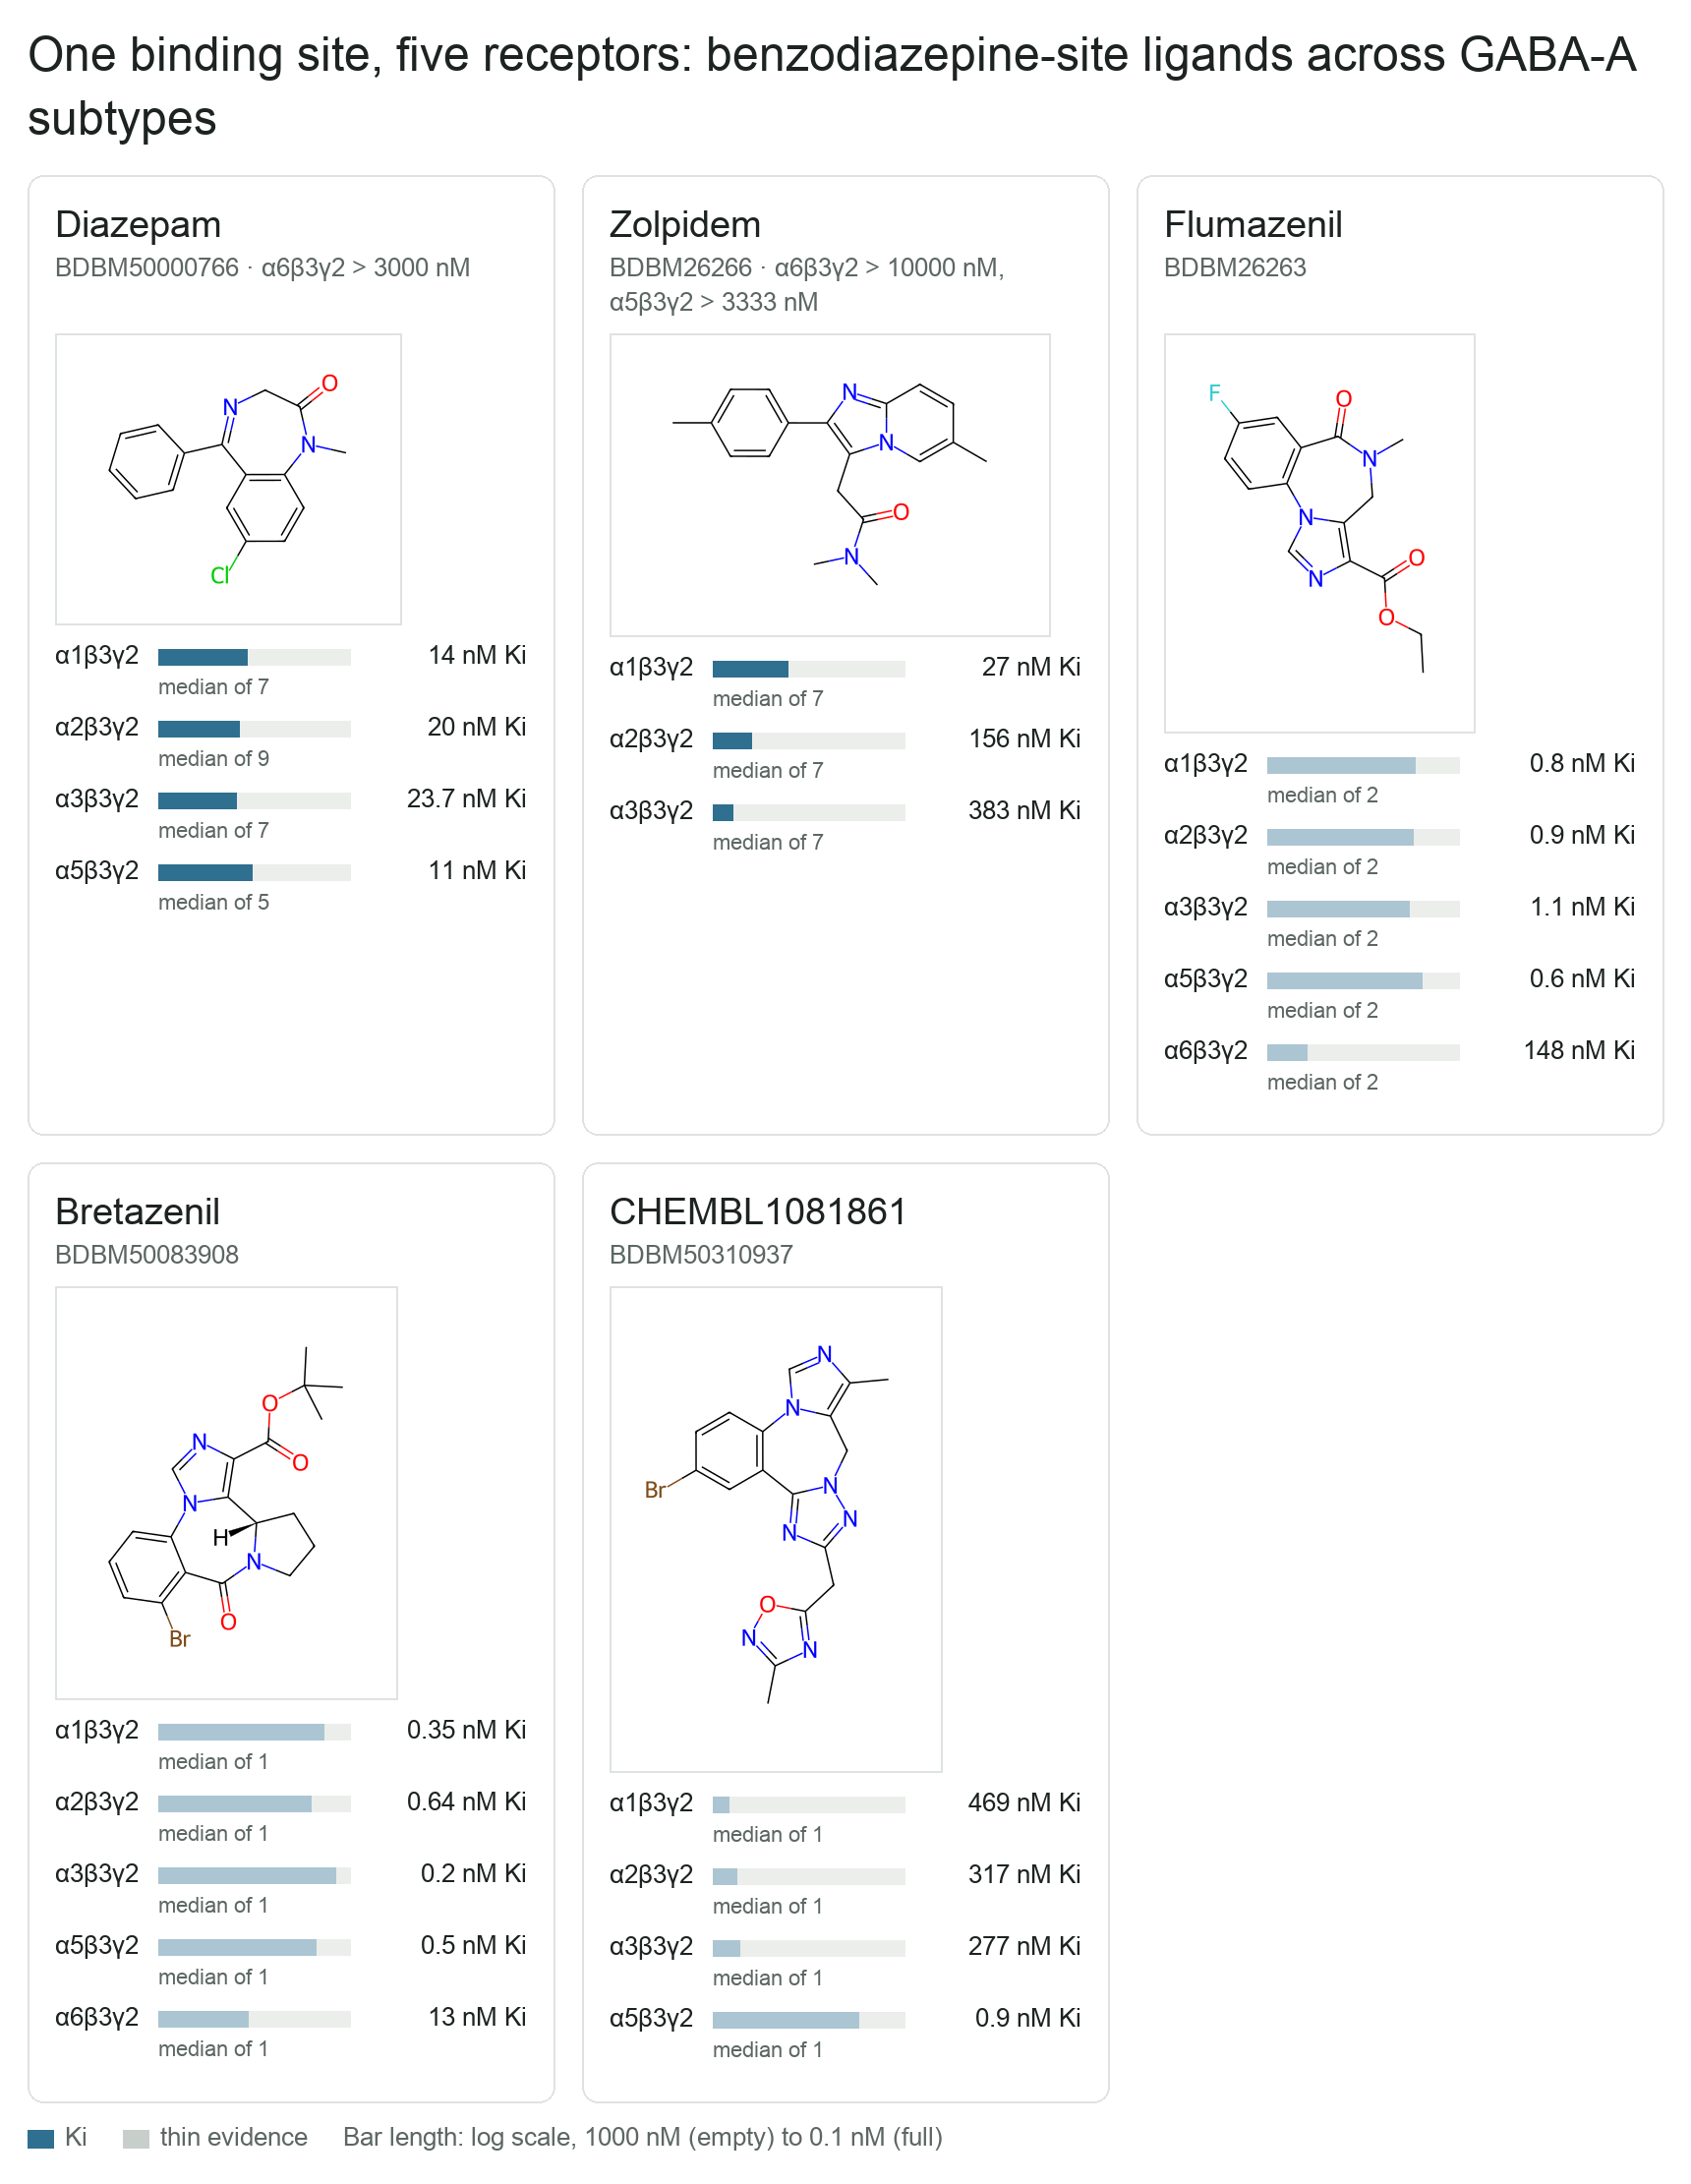

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'One binding site, five receptors: benzodiazepine-site ligands across GABA-A subtypes',
    'compounds': [
        {
            'smiles': 'CN1c2ccc(cc2C(=NCC1=O)c3ccccc3)Cl',
            'title': 'Diazepam',
            'subtitle': 'BDBM50000766 · α6β3γ2 > 3000 nM',
            'bars': [
                {'label': 'α1β3γ2', 'value_nm': 14.0, 'type': 'Ki', 'note': 'median of 7'},
                {'label': 'α2β3γ2', 'value_nm': 20.0, 'type': 'Ki', 'note': 'median of 9'},
                {'label': 'α3β3γ2', 'value_nm': 23.7, 'type': 'Ki', 'note': 'median of 7'},
                {'label': 'α5β3γ2', 'value_nm': 11.0, 'type': 'Ki', 'note': 'median of 5'},
            ],
        },
        {
            'smiles': 'CN(C)C(=O)Cc1c(nc2ccc(C)cn12)-c1ccc(C)cc1',
            'title': 'Zolpidem',
            'subtitle': 'BDBM26266 · α6β3γ2 > 10000 nM, α5β3γ2 > 3333 nM',
            'bars': [
                {'label': 'α1β3γ2', 'value_nm': 27.0, 'type': 'Ki', 'note': 'median of 7'},
                {'label': 'α2β3γ2', 'value_nm': 156.0, 'type': 'Ki', 'note': 'median of 7'},
                {'label': 'α3β3γ2', 'value_nm': 383.0, 'type': 'Ki', 'note': 'median of 7'},
            ],
        },
        {
            'smiles': 'CCOC(=O)c1ncn-2c1CN(C)C(=O)c1cc(F)ccc-21',
            'title': 'Flumazenil',
            'subtitle': 'BDBM26263',
            'bars': [
                {'label': 'α1β3γ2', 'value_nm': 0.8, 'type': 'Ki', 'note': 'median of 2', 'faint': True},
                {'label': 'α2β3γ2', 'value_nm': 0.9, 'type': 'Ki', 'note': 'median of 2', 'faint': True},
                {'label': 'α3β3γ2', 'value_nm': 1.1, 'type': 'Ki', 'note': 'median of 2', 'faint': True},
                {'label': 'α5β3γ2', 'value_nm': 0.6, 'type': 'Ki', 'note': 'median of 2', 'faint': True},
                {'label': 'α6β3γ2', 'value_nm': 148.0, 'type': 'Ki', 'note': 'median of 2', 'faint': True},
            ],
        },
        {
            'smiles': 'CC(C)(C)OC(=O)c1ncn-2c1[C@@H]1CCCN1C(=O)c1c(Br)cccc-21',
            'title': 'Bretazenil',
            'subtitle': 'BDBM50083908',
            'bars': [
                {'label': 'α1β3γ2', 'value_nm': 0.35, 'type': 'Ki', 'note': 'median of 1', 'faint': True},
                {'label': 'α2β3γ2', 'value_nm': 0.64, 'type': 'Ki', 'note': 'median of 1', 'faint': True},
                {'label': 'α3β3γ2', 'value_nm': 0.2, 'type': 'Ki', 'note': 'median of 1', 'faint': True},
                {'label': 'α5β3γ2', 'value_nm': 0.5, 'type': 'Ki', 'note': 'median of 1', 'faint': True},
                {'label': 'α6β3γ2', 'value_nm': 13.0, 'type': 'Ki', 'note': 'median of 1', 'faint': True},
            ],
        },
        {
            'smiles': 'Cc1noc(Cc2nc3-c4cc(Br)ccc4-n4cnc(C)c4Cn3n2)n1',
            'title': 'CHEMBL1081861',
            'subtitle': 'BDBM50310937',
            'bars': [
                {'label': 'α1β3γ2', 'value_nm': 469.0, 'type': 'Ki', 'note': 'median of 1', 'faint': True},
                {'label': 'α2β3γ2', 'value_nm': 317.0, 'type': 'Ki', 'note': 'median of 1', 'faint': True},
                {'label': 'α3β3γ2', 'value_nm': 277.0, 'type': 'Ki', 'note': 'median of 1', 'faint': True},
                {'label': 'α5β3γ2', 'value_nm': 0.9, 'type': 'Ki', 'note': 'median of 1', 'faint': True},
            ],
        },
    ],
    'columns': 3,
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

BindingDB stores it as a **complex target**: a target made of several protein components, with its own id and no UniProt accession of its own. The GABA-A receptor that diazepam binds is **Gamma-aminobutyric acid receptor subunit alpha-1/beta-3/gamma-2**, complex id 386, assembled from three separate polymer entries:

| Component | UniProt | Polymer id |
|---|---|---|
| GABA-A receptor subunit α1 | P14867 | 5521 |
| GABA-A receptor subunit β3 | P28472 | 50001801 |
| GABA-A receptor subunit γ2 | P18507 | 50000214 |

It holds 1,325 measurements on 1,111 compounds (1,258 Ki, 55 EC50, 12 IC50) and links 153 PDB entries. This is the right unit for this question: the benzodiazepine site is a pocket at the interface between the α and the γ2 subunit, so neither protein has the site on its own, and an affinity measured against "GABRA1" alone would not describe it.

**Each subunit combination is its own target.** 84 GABA-A complex entries with measurements cover 2,399 compounds in 7,318 measurements. The five that matter for benzodiazepine-site pharmacology are the αxβ3γ2 receptors:

| Complex | Target id | Compounds | Measurements |
|---|---|---|---|
| α5β3γ2 | 50000048 | 1,213 | 1,383 |
| α1β3γ2 | 386 | 1,111 | 1,325 |
| α3β3γ2 | 50000037 | 734 | 899 |
| α2β3γ2 | 50000045 | 617 | 779 |
| α6β3γ2 | 50000040 | 216 | 317 |

The remainder are β1, β2, γ1, δ and α4 variants, a few two-subunit combinations, and 34 engineered constructs, such as the cysteine mutants used for accessibility mapping (`...gamma-2 [40-467,A118C]`). Those are legitimate targets but not what you want in a subtype comparison, so filter by name, not by a text match on "GABA" (the names use both "GABA-A receptor" and "Gamma-aminobutyric acid receptor subunit"). One more caution: a few small duplicate entries of the same subunit combination exist (for example α1β3γ2 also appears as 50000041, 50017444 and 50017008, with 31, 28 and 6 measurements, and α5β3γ2 as 50000146 with 36), so the five entries above hold most but not all of each subtype's data.

**Subtype selectivity of the benzodiazepine-site drugs**

Figure 1 draws each drug with its median Ki against the five receptors (the compounds do not share a core of 8 or more atoms, so the drawings are not aligned), and the four classic ligands fall into three distinct patterns.

- **Diazepam binds all four benzodiazepine-sensitive subtypes about equally**: 11 to 24 nM across α1, α2, α3 and α5 (14, 20, 23.7 and 11 nM). Its sedative, anxiolytic, myorelaxant and amnesic effects come from the same molecule hitting all of them, which is the pharmacological basis for the search for subtype-selective successors. At α6 there is a single record, Ki > 3 µM.
- **Zolpidem is the α1-preferring hypnotic**, and the data reproduce the textbook profile: Ki 27 nM at α1, 156 nM at α2, 383 nM at α3, and no measurable binding at α5 or α6 (six records at α5, all reported as Ki > 3.333 µM, and three at α6 reported as > 10 µM). That is why it has no bars for those two.
- **Flumazenil, the overdose antidote, binds everything that has a benzodiazepine site**: 0.6 to 1.1 nM at α1, α2, α3 and α5, and then drops 150- to 250-fold to 148 nM at α6. The α6 subunit carries an arginine where the other α subunits carry a histidine, and that one residue is what makes α6 receptors benzodiazepine-insensitive. The complex data show the structural fact directly.
- **Bretazenil is the exception that proves it.** This partial agonist binds α1, α2, α3 and α5 at 0.2 to 0.64 nM and keeps 13 nM affinity at α6, only 20- to 65-fold weaker instead of 150- to 250-fold. It is the probe compound used precisely because it tolerates the arginine. (Each of its values rests on a single measurement.)

**What the subtype split is for.** Ranking compounds by the ratio of α1 to α5 Ki finds how far selectivity has been pushed: CHEMBL1081861, an imidazo-triazolo-benzodiazepine from PMID 19740657, reaches Ki 0.9 nM at α5 with 469 nM at α1 (521-fold, the top of the ranking), and a 2025 patent series (US20250136581) of triazolylmethoxy-pyridazines reaches 456-fold on the same comparison (178 nM at α1, 0.39 nM at α5), with several more members above 150-fold. α5-selective negative modulators are pursued for cognitive impairment, where diazepam's α5 activity is the liability rather than the goal. None of this is visible if a database stores one "GABA-A receptor" target.

**Querying a complex.** Every curated tool takes `target_kind: "complex"` with the complex id: `get_target` for the record above, `find_ligands_for_target` for its ligands. The most potent compound on α5β3γ2 is a pyrazoloquinolinone with Ki 0.08 nM (PMID 10633039). In SQL the equivalent is `activity.complexid` instead of `activity.polymerid`; the two columns are mutually exclusive, and `complex_component` maps a complex to its polymers.

**Lesson: "complex" means more than one component, not necessarily an assembly.** The same target kind also stores fusion proteins. BCR-ABL, for example, is complex 261 with components BCR and ABL1 (two components), yet in reality a single polypeptide from a chromosomal translocation, not two proteins in a complex. And an obligate heterodimer like CDK4/cyclin D1 (complex 93) sits in the same table as a receptor with several subunits. Read the `component_count` and the component list before deciding what a complex target physically is.

**Lesson: the same pharmacology is split between polymer and complex entries.** The α1 subunit also exists as a standalone polymer target (5521) with 540 measurements on 447 compounds, most of them electrophysiology recordings where the paper named only the α subunit. A survey of "what binds GABA-A receptors" has to collect both kinds of entry, or it will silently miss one of them.

**How this was answered**
- `search_targets` for "GABA-A receptor" returned both kinds of entry side by side, polymer subunits and complex receptors, each row labelled with its `target_kind`.
- `get_target` with `target_id: 386` and `target_kind: "complex"` gave the components, the measurement counts by type and the PDB links.
- A `run_sql` query over `target` listed the GABA-A complexes by size.
- `search_compounds` resolved diazepam, zolpidem, flumazenil, bretazenil and CHEMBL1081861 by name.
- A second `run_sql` query took each drug's median exact Ki and its censored ('>') records on the five αxβ3γ2 complexes; a third ranked compounds by the ratio of their α1 to their α5 Ki.
- `find_ligands_for_target` with `target_kind: "complex"` listed the most potent α5β3γ2 ligands, and `draw_structure_grid` drew Figure 1.

**Try next**
- "Which subtype does eszopiclone prefer?" Check whether its complex data sit only on cysteine-mutant constructs, so that the plain subtypes have nothing to compare.
- "Compare CDK4/cyclin D1 with CDK2/cyclin E1 for the CDK4/6 drugs" (complexes 93 and 81)
- Example 3.3 does the same comparison across point mutants of one protein instead of subunit compositions

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 14 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 3.5 — Protein complexes: GABA-A receptor subtypes, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```